# What the satellite calibration does nearshore (2013)

WHACS_cal (07b: directional energy fit + quantile mapping on IMOS altimetry) against the raw
WHACS: how much the offshore change survives the propagation to the coast, and whether it
brings the buoys closer. Spectral metamodel (the product), MDA 600, CODEC.

In [ ]:
import sys

sys.path.insert(0, "..")  # the case folder (utils/)

import matplotlib.pyplot as plt
import pandas as pd
import results as rs
from IPython.display import display

pd.set_option("display.width", 200)
pd.set_option("display.precision", 3)

In [2]:
from utils.config import open_offshore_waves

off_raw = open_offshore_waves("WHACS").sel(time=rs.PERIOD)["hs"].load()
off_cal = open_offshore_waves("WHACS_cal").sel(time=rs.PERIOD)["hs"].load()
iso_raw = rs.metamodel("WHACS", "isobaths", True)
iso_cal = rs.metamodel("WHACS_cal", "isobaths", True)
print(iso_raw.sizes)

Frozen({'time': 8760, 'sites': 4977})


## 1 · Offshore vs nearshore change

Quantiles of Hs at the goals and at each isobath, raw and calibrated, and their difference.

In [ ]:
qs = [0.5, 0.9, 0.99, 0.999]
rows = {
    "goals (offshore)": (
        off_raw.quantile(qs, "time").median("goal"),
        off_cal.quantile(qs, "time").median("goal"),
    )
}
for label in ("20m", "10m", "5m"):
    sel = iso_raw["site_label"].values == label
    rows[label] = (
        iso_raw["hs"].isel(sites=sel).quantile(qs, "time").median("sites"),
        iso_cal["hs"].isel(sites=sel).quantile(qs, "time").median("sites"),
    )
table = pd.DataFrame(
    {name: (cal - raw).values for name, (raw, cal) in rows.items()},
    index=[f"p{100 * q:g}" for q in qs],
).T
print("WHACS_cal − WHACS, median over goals / sites (m)")
display(table)

WHACS_cal − WHACS, median over goals / sites (m)


,p50,p90,p99,p99.9
goals (offshore),5.056e-03,0.104,0.542,1.686
20m,3.707e-03,0.036,0.224,0.958
10m,2.120e-03,0.037,0.145,0.385
5m,7.879e-04,0.047,0.159,0.405


## 2 · Map of the change

Mean and p99 of Hs, WHACS_cal − WHACS, at the isobaths.

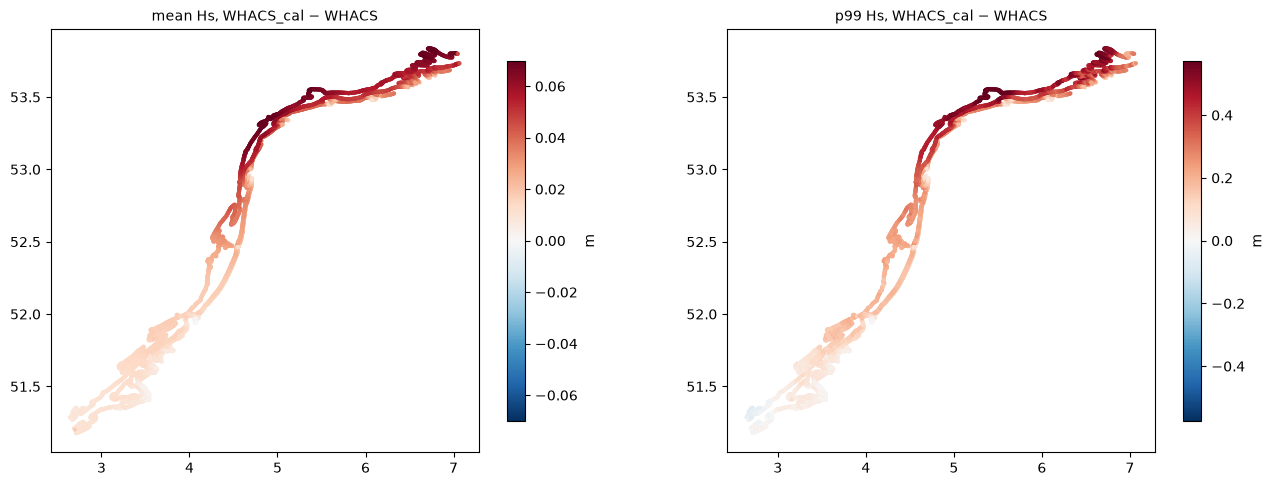

In [ ]:
d = iso_cal["hs"] - iso_raw["hs"]
coords = iso_raw["hs"].isel(time=0, drop=True).coords
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
rs.plot_site_map(
    d.mean("time").assign_coords(coords), "mean Hs, WHACS_cal − WHACS", "m", ax=axes[0]
)
p99 = (
    (iso_cal["hs"].quantile(0.99, "time") - iso_raw["hs"].quantile(0.99, "time"))
    .drop_vars("quantile")
    .assign_coords(coords)
)
rs.plot_site_map(p99, "p99 Hs, WHACS_cal − WHACS", "m", ax=axes[1])
plt.show()

## 3 · Against the buoys

Spectral metamodel and dynamic runs of both sources vs the buoys: median metrics and the
storm tail (quantiles).

In [5]:
buoy = rs.buoys(["hs"])
both = {}
for off in rs.OFFSHORE:
    est = rs.estimates_at_buoys(off, buoy)
    for name in ("offshore", "metamodel spectral", "dynamic no wind", "dynamic wind"):
        if name in est:
            both[f"{name} · {off}"] = est[name]
display(rs.median_metrics(buoy, both)[["n", "bias", "rmse", "si", "r2"]])
display(rs.quantile_bias(buoy, both))

,n,bias,rmse,si,r2
offshore · WHACS,7065.0,0.248,0.392,0.277,0.502
metamodel spectral · WHACS,7065.0,-0.170,0.353,0.253,0.692
dynamic no wind · WHACS,7065.0,-0.199,0.349,0.245,0.647
dynamic wind · WHACS,6727.0,0.112,0.284,0.199,0.805
offshore · WHACS_cal,7065.0,0.274,0.426,0.265,0.444
metamodel spectral · WHACS_cal,7065.0,-0.125,0.340,0.257,0.690
dynamic no wind · WHACS_cal,7065.0,-0.161,0.332,0.248,0.655
dynamic wind · WHACS_cal,6795.0,0.139,0.286,0.194,0.797


quantile,p50,p90,p99,p99.9
offshore · WHACS,0.239,0.528,0.358,0.336
metamodel spectral · WHACS,-0.102,-0.193,-0.515,-0.686
dynamic no wind · WHACS,-0.137,-0.244,-0.528,-0.976
dynamic wind · WHACS,0.193,0.207,0.039,-0.443
offshore · WHACS_cal,0.244,0.553,0.745,0.918
metamodel spectral · WHACS_cal,-0.102,-0.105,-0.256,-0.223
dynamic no wind · WHACS_cal,-0.118,-0.150,-0.386,-0.592
dynamic wind · WHACS_cal,0.188,0.222,0.150,-0.113
